# Regresión logística con SMOTE-NC

**Inteligencia Artificial Aplicada (1INF62) — Pontificia Universidad Católica del Perú, 2026-2**

**Integrantes:** Aguilera, Jair · Araujo, Luis · Condori, Nilton · Vilcayauri, Pedro

---

### Abstract

Este notebook entrena la regresión logística sobre un conjunto de entrenamiento sobremuestreado con **SMOTE-NC**, siguiendo a Khan et al. (2022), cuyo mejor clasificador fue la regresión logística con SMOTE. SMOTE crea casos sintéticos de bajo peso interpolando entre vecinos; la variante NC (nominal-continuous) se usa porque 7 de las 9 features son categóricas. El sobremuestreo se aplica **solo al train**; validación y test conservan su distribución real. La proporción de sobremuestreo, la fuerza de la regularización (`C`) y su tipo (L1 o L2) se eligen por AUC-PR en validación, y el test (2024–2025) se usa una sola vez. Se compara con el baseline (regresión logística simple).

**Resultado principal:** se eligió la proporción 0.25 con L2 y C = 0.0001. En el test (2024–2025) la regresión con SMOTE-NC discrimina igual que el baseline (AUC-ROC 0.907 frente a 0.908; AUC-PR 0.677 en ambos). Con el umbral 0.5 queda en un punto intermedio: recall 0.63 y precisión 0.62, con el mejor F1 de las tres regresiones logísticas (0.62).

### Estructura del notebook

1. Configuración del entorno
2. Datos y partición temporal
3. Ajuste de hiperparámetros (proporción de sobremuestreo × C × tipo de penalización)
4. Modelo final y evaluación en test
5. Interpretación
6. Limitaciones

## 1. Configuración del entorno

El notebook funciona en Google Colab y en local, igual que el EDA. En Colab clona o actualiza el repositorio; en local asume que se ejecuta desde `proyecto/notebooks/`. Todo el preprocesamiento se importa de `src/preprocessing.py`, para que los cinco modelos usen exactamente los mismos datos y la misma partición. Además se requiere `imbalanced-learn` para SMOTE-NC; Colab suele traerlo y, si no, la celda lo instala.

> **Tiempo de ejecución:** SMOTE-NC sobre los 3.2 millones de registros de train es la parte lenta (en Colab tomó unos 39 minutos generar los casos sintéticos y unos 21 la grilla; los ajustes más lentos son L2 con C = 0.001, de unos 8 minutos cada uno). Conviene ejecutar el notebook de una vez y con la pestaña abierta.

In [1]:
import sys, gc, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
try:
    import imblearn
except ImportError:
    !pip install -q imbalanced-learn
from imblearn.over_sampling import SMOTENC

warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/jasnai10/AI_Project.git"

if IN_COLAB:
    if not Path("/content/AI_Project").exists():
        !git clone -q {REPO_URL} /content/AI_Project
    else:
        !git -C /content/AI_Project pull -q
    ROOT = Path("/content/AI_Project/proyecto")
else:
    ROOT = Path.cwd().parent

sys.path.insert(0, str(ROOT))
from src.preprocessing import (cargar_cnv, limpiar, seleccionar_features, columnas_features,
                               dividir_temporal, construir_preprocesador, SEMILLA)

pd.set_option("display.float_format", "{:,.4f}".format)
print("Entorno:", "Colab" if IN_COLAB else "local", "| ROOT:", ROOT)

Entorno: Colab | ROOT: /content/AI_Project/proyecto


## 2. Datos y partición temporal

Se carga el CNV original desde `data/raw/dataset.zip` y se aplican `limpiar()` y `seleccionar_features()` (9 features, casos completos). La partición es la **temporal** definida en el EDA:

| Conjunto | Años | Uso |
|---|---|---|
| Train | 2015–2023 (80% al azar, estratificado) | Ajustar el modelo y el preprocesador |
| Validación | 2015–2023 (20% restante) | Elegir la proporción de sobremuestreo, C y el tipo de penalización |
| Test | 2024–2025 | Evaluación final, una sola vez |

El test simula el uso real: entrenar con el pasado y predecir el futuro. Su prevalencia (6.81%) es mayor que la de train (6.32%), así que la precisión y el F1 en test cambian de nivel aunque el modelo sea el mismo. Por eso los modelos se comparan sobre todo con métricas que no dependen de la prevalencia ni del umbral. 2025 llega hasta el 30/11/2025, sin diciembre.

In [2]:
df_raw, _ = cargar_cnv(ruta_zip=ROOT / "data" / "raw" / "dataset.zip")
df = limpiar(df_raw)
del df_raw; gc.collect()

X, y = seleccionar_features(df, target="bajo_peso")
X_tr, X_val, X_te, y_tr, y_val, y_te = dividir_temporal(X, y, df["anio"])
anio = df["anio"]
resumen = pd.DataFrame({
    "años": [f"{anio[X_tr.index].min()}-{anio[X_tr.index].max()}",
             f"{anio[X_val.index].min()}-{anio[X_val.index].max()}",
             f"{anio[X_te.index].min()}-{anio[X_te.index].max()}"],
    "registros": [len(y_tr), len(y_val), len(y_te)],
    "casos_bajo_peso": [int(y_tr.sum()), int(y_val.sum()), int(y_te.sum())],
    "prevalencia_%": [y_tr.mean() * 100, y_val.mean() * 100, y_te.mean() * 100]},
    index=["train", "validación", "test"])
del X, y, df, anio; gc.collect()
cat_cols, num_cols = columnas_features()
resumen.round(2)

Cargado CNV_MINSA_CORTE_30112025.csv: 4,874,510 filas, 22 columnas | filas reparadas: 388 | descartadas: 0
limpiar(): 4,874,510 → 4,871,486 filas (eliminadas 3,024 sin peso válido) | prevalencia de bajo peso: 6.38%
target=bajo_peso | 9 features | casos completos: 4,764,960 de 4,871,486 (97.81%)


,años,registros,casos_bajo_peso,prevalencia_%
train,2015-2023,3237829,204500,6.3200
validación,2015-2023,809458,51125,6.3200
test,2024-2025,717673,48907,6.8100


## 3. Ajuste de hiperparámetros

**Qué hace SMOTE-NC.** Para cada caso de bajo peso elige uno de sus 5 vecinos más cercanos (también de bajo peso) y crea un caso sintético entre ambos: las numéricas se interpolan y las categóricas toman la categoría más frecuente entre los vecinos. La interpolación no tendría sentido en categóricas (daría, por ejemplo, "departamento = 0.37").

**Cómo se evita la fuga de información.** El sobremuestreo se aplica **solo al train**. Validación y test no reciben casos sintéticos, igual que en Khan et al. No se usa `class_weight`, porque el balanceo ya lo hace SMOTE-NC. Como en el notebook 03, la función `regresion_logistica` indica L1 o L2 de la forma que corresponde a la versión de scikit-learn instalada (`l1_ratio` en ≥ 1.8, `penalty` en versiones anteriores como la de Colab).

**Procedimiento.** Las categóricas se codifican como enteros (`OrdinalEncoder`) y las numéricas se estandarizan, porque SMOTE-NC necesita un arreglo numérico y las distancias no deben depender de la escala. Luego se sobremuestrea, y recién después se aplica el one-hot y se ajusta la regresión (el mismo preprocesamiento final que en el baseline, 53 columnas).

**Hiperparámetros.** El modelo es un pipeline de dos piezas, y en ambas hay hiperparámetros que cambian lo que el modelo aprende:

| Pieza | Hiperparámetro | Qué controla | Valores |
|---|---|---|---|
| SMOTE-NC | `sampling_strategy` | Proporción casos/no casos después de sobremuestrear: cuántos casos sintéticos se crean. Es lo que Khan et al. varían. | 0.25 (train con 20% de casos) y 0.5 (33%) |
| Regresión logística | `C` | Inverso de la fuerza de la regularización. | 0.0001 y 0.001 |
| Regresión logística | `l1_ratio` | Tipo de penalización: `0` = L2 (encoge todos los coeficientes), `1` = L1 (puede dejar coeficientes en cero). | 0 (L2) y 1 (L1) |

Son 2 × 2 × 2 = 8 ajustes. El rango de `C` se tomó del notebook 03: con `C ≥ 0.01` el modelo ya no cambia y con `C = 0.00001` subajusta, así que se prueba la zona intermedia. `C = 0.01` se descartó porque en una prueba previa con estos datos dio el mismo AUC-PR que `C = 0.001`, pero `saga` necesitó unas 540 iteraciones (unos 15 minutos) para converger con L2. El solver es `saga` en todas las combinaciones (el único que admite L1 y L2 con la misma fórmula); es un parámetro del algoritmo, no del modelo. No se usa `class_weight`, porque el balanceo ya lo hace SMOTE-NC.

**Qué queda fijo y por qué.** `k_neighbors = 5` (valor por defecto): también es un hiperparámetro del modelo, pero cada valor obliga a regenerar los casos sintéticos, que es la parte más lenta. No se prueba el balance total (`sampling_strategy = 1.0`): generaría unos 2.8 millones de casos sintéticos y el pico de memoria de SMOTE-NC no entra en el entorno de ejecución. Tampoco se combinan SMOTE y `class_weight` (sería balancear dos veces).

**Cómo se genera cada proporción.** SMOTE-NC se ejecuta **una sola vez** con la proporción 0.5; la proporción 0.25 usa una submuestra aleatoria de esos casos sintéticos (equivale a pedirla directamente, porque cada caso sintético se genera de forma independiente). Las métricas de train se calculan sobre el train **real**, sin casos sintéticos. La tabla incluye las iteraciones de cada ajuste (para comprobar que convergió) y cuántos coeficientes quedaron en cero.

**Criterio de selección:** AUC-PR en validación; todo lo que quede a menos de 0.001 del mejor es un empate. Entre empates se prefiere la menor proporción de sobremuestreo (menos datos sintéticos), luego L2 y luego el C menor. El modelo final es el elegido, ya entrenado con train (no se repite el sobremuestreo).

### Métricas

- **AUC-ROC y AUC-PR:** no dependen del umbral. Son las métricas principales para comparar modelos. El AUC-PR de un clasificador al azar es igual a la prevalencia (0.0681 en test), no a 0.5.
- **Precisión, recall y F1 con umbral 0.5:** el umbral **no se calibra**, igual que en Almeida et al. (2026), Khan et al. (2022) y Ranjbar et al. (2023), que usaron el valor por defecto de sus librerías. Así las cifras son comparables con las de los papers.
- **Accuracy:** solo como referencia. Con 6-7% de prevalencia, predecir siempre "no bajo peso" ya da cerca de 93%.

scikit-learn 1.6.1
SMOTE-NC tardó 2346 s: train 3,237,829 -> 4,549,993 filas (1,312,164 casos sintéticos)
sampling_strategy=0.25: 3,791,661 filas, 758,332 casos (20.0%)
sampling_strategy=0.5: 4,549,993 filas, 1,516,664 casos (33.3%)


,estrategia,penalizacion,C,auc_pr_train,auc_pr_val,auc_roc_val,precision_val,recall_val,f1_val,accuracy_val,coef_en_cero,iteraciones,seg
0,0.2500,L2,0.0001,0.6669,0.6659,0.9031,0.6343,0.6130,0.6234,0.9532,0,14,47.5359
1,0.2500,L2,0.001,0.6673,0.6662,0.9045,0.6201,0.6218,0.6209,0.9521,0,153,494.0502
2,0.2500,L1,0.0001,0.6611,0.6602,0.8991,0.6223,0.6162,0.6193,0.9521,46,13,47.9541
3,0.2500,L1,0.001,0.6670,0.6659,0.9038,0.6229,0.6222,0.6225,0.9523,18,15,61.0224
4,0.5000,L2,0.0001,0.6670,0.6659,0.9038,0.4630,0.7053,0.5591,0.9297,0,14,62.7755
5,0.5000,L2,0.001,0.6667,0.6655,0.9047,0.4584,0.7098,0.5571,0.9287,0,103,440.1359
6,0.5000,L1,0.0001,0.6628,0.6618,0.9002,0.4588,0.7043,0.5556,0.9288,42,14,68.2495
7,0.5000,L1,0.001,0.6668,0.6656,0.9045,0.4597,0.7087,0.5577,0.9290,12,14,67.8025


Todos los ajustes convergieron: True


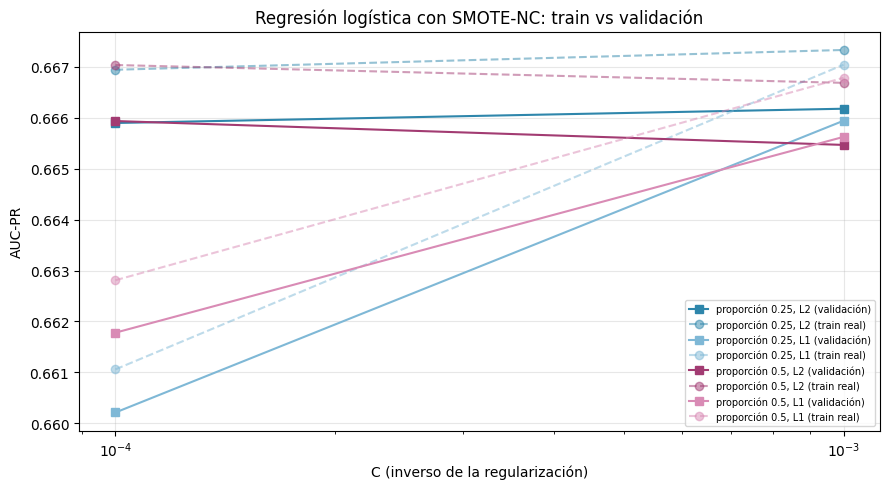

Combinaciones empatadas con el mejor AUC-PR: 6 de 8
Elegido: sampling_strategy=0.25, penalización L2, C=0.0001


In [3]:
UMBRAL = 0.5   # umbral por defecto, como en los papers (no se calibra)

def evaluar(y_true, p, umbral=UMBRAL):
    pred = (p >= umbral).astype(int)
    return {"auc_roc": roc_auc_score(y_true, p),
            "auc_pr": average_precision_score(y_true, p),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0),
            "accuracy": accuracy_score(y_true, pred)}

import sklearn
VERSION_SK = tuple(int(x) for x in sklearn.__version__.split(".")[:2])

def regresion_logistica(C, penalizacion, **kwargs):
    # Regresión logística con penalización L1 o L2 según la versión de scikit-learn.
    # En >= 1.8 el tipo se indica con l1_ratio (penalty está deprecado); en versiones anteriores
    # (como la que trae Colab) se indica con penalty, porque ahí l1_ratio se ignora salvo con elastic-net.
    if VERSION_SK >= (1, 8):
        return LogisticRegression(C=C, l1_ratio={"L2": 0, "L1": 1}[penalizacion], **kwargs)
    return LogisticRegression(C=C, penalty=penalizacion.lower(), **kwargs)

print("scikit-learn", sklearn.__version__)

n_cat = len(cat_cols)
ordinal = ColumnTransformer([("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat_cols),
                             ("num", StandardScaler(), num_cols)]).fit(X_tr)      # fit SOLO con train
Z_tr, Z_val = ordinal.transform(X_tr), ordinal.transform(X_val)                  # categóricas = columnas 0..n_cat-1

def preprocesador_ohe():
    # one-hot para las categóricas (ya codificadas como enteros); numéricas sin tocar (ya estandarizadas)
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), list(range(n_cat))),
                              ("num", "passthrough", list(range(n_cat, n_cat + len(num_cols))))])

t0 = time.time()
Z_all, y_all = SMOTENC(categorical_features=list(range(n_cat)), sampling_strategy=0.5,
                       k_neighbors=5, random_state=SEMILLA).fit_resample(Z_tr, y_tr)   # SOLO train
y_all = np.asarray(y_all)
n_real, n_may, n_min = len(y_tr), int((y_tr == 0).sum()), int(y_tr.sum())
n_sint_total = len(y_all) - n_real                   # SMOTENC devuelve primero los reales y luego los sintéticos
t_smote = time.time() - t0
print(f"SMOTE-NC tardó {t_smote:.0f} s: train {n_real:,} -> {len(y_all):,} filas ({n_sint_total:,} casos sintéticos)")
rng = np.random.RandomState(SEMILLA)

filas, modelos = [], {}
for estrategia in [0.25, 0.5]:
    n_sint = int(round(estrategia * n_may)) - n_min
    idx = np.concatenate([np.arange(n_real), n_real + np.sort(rng.choice(n_sint_total, n_sint, replace=False))])
    Z_res, y_res = Z_all[idx], y_all[idx]
    print(f"sampling_strategy={estrategia}: {len(y_res):,} filas, {int(y_res.sum()):,} casos ({y_res.mean() * 100:.1f}%)")
    ohe = preprocesador_ohe().fit(Z_res)
    R, Rtr, Rval = ohe.transform(Z_res), ohe.transform(Z_tr), ohe.transform(Z_val)
    for penalizacion in ["L2", "L1"]:
        for C in [1e-4, 1e-3]:
            t0 = time.time()
            m = regresion_logistica(C, penalizacion, solver="saga", max_iter=1000,
                                    random_state=SEMILLA).fit(R, y_res)
            p_tr, p_val = m.predict_proba(Rtr)[:, 1], m.predict_proba(Rval)[:, 1]
            v = evaluar(y_val, p_val)
            modelos[(estrategia, penalizacion, C)] = (ohe, m)
            filas.append({"estrategia": estrategia, "penalizacion": penalizacion, "C": C,
                          "auc_pr_train": average_precision_score(y_tr, p_tr), "auc_pr_val": v["auc_pr"],
                          "auc_roc_val": v["auc_roc"],
                          "precision_val": v["precision"], "recall_val": v["recall"], "f1_val": v["f1"],
                          "accuracy_val": v["accuracy"],
                          "coef_en_cero": int((m.coef_ == 0).sum()), "iteraciones": int(m.n_iter_[0]),
                          "seg": time.time() - t0})
    del Z_res, y_res, R, Rtr, Rval; gc.collect()
del Z_all, y_all, Z_tr, Z_val; _ = gc.collect()
res = pd.DataFrame(filas)
display(res.round(4).assign(C=res["C"].map("{:g}".format)))   # C en notación legible
print("Todos los ajustes convergieron:", bool((res["iteraciones"] < 1000).all()))

fig, ax = plt.subplots(figsize=(9, 5))
colores = {(0.25, "L2"): "#2E86AB", (0.25, "L1"): "#7FB8D6", (0.5, "L2"): "#A23B72", (0.5, "L1"): "#D98BB5"}
for (e, pen), col in colores.items():
    d = res[(res.estrategia == e) & (res.penalizacion == pen)]
    ax.plot(d.C, d.auc_pr_val, "s-", color=col, label=f"proporción {e}, {pen} (validación)")
    ax.plot(d.C, d.auc_pr_train, "o--", color=col, alpha=.5, label=f"proporción {e}, {pen} (train real)")
ax.set_xscale("log"); ax.set_xlabel("C (inverso de la regularización)"); ax.set_ylabel("AUC-PR")
ax.set_title("Regresión logística con SMOTE-NC: train vs validación")
ax.legend(fontsize=7); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

empates = res[res["auc_pr_val"] >= res["auc_pr_val"].max() - 0.001].copy()
empates["p"] = empates["penalizacion"].map({"L2": 0, "L1": 1})
mejor = empates.sort_values(["estrategia", "p", "C"]).iloc[0]
print(f"Combinaciones empatadas con el mejor AUC-PR: {len(empates)} de {len(res)}")
print(f"Elegido: sampling_strategy={mejor['estrategia']}, penalización {mejor['penalizacion']}, C={mejor['C']}")

## 4. Modelo final y evaluación en test

El modelo final es el elegido en la sección 3, ya entrenado con el train sobremuestreado. Se arma un `Pipeline` con los pasos ya ajustados (codificación ordinal y escalado, one-hot y regresión) para predecir sobre datos originales; al predecir no se sobremuestrea nada. Se evalúa **una sola vez** en el test (2024–2025), junto al baseline entrenado con los mismos datos.

In [4]:
ohe_final, clf_final = modelos[(float(mejor["estrategia"]), mejor["penalizacion"], float(mejor["C"]))]
final = Pipeline([("ordinal", ordinal), ("ohe", ohe_final), ("clf", clf_final)])   # pasos ya ajustados
baseline = Pipeline([("prep", construir_preprocesador()),
                     ("clf", LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000, random_state=SEMILLA))]).fit(X_tr, y_tr)

probas_te = {"RL con SMOTE-NC": final.predict_proba(X_te)[:, 1],
             "RL simple (baseline)": baseline.predict_proba(X_te)[:, 1]}
metricas = pd.DataFrame({k: evaluar(y_te, p) for k, p in probas_te.items()}).T
display(metricas.round(4))
print("Prevalencia en test (AUC-PR de un clasificador al azar):", round(y_te.mean(), 4))
for k, p in probas_te.items():
    cm = confusion_matrix(y_te, (p >= UMBRAL).astype(int))
    print(f"{k}: matriz de confusión [[TN FP], [FN TP]] = {cm.tolist()} | detecta {cm[1, 1]:,} de {int(y_te.sum()):,} casos")

,auc_roc,auc_pr,precision,recall,f1,accuracy
RL con SMOTE-NC,0.9071,0.6770,0.6183,0.6296,0.6239,0.9483
RL simple (baseline),0.9081,0.6774,0.8204,0.4732,0.6002,0.9570


Prevalencia en test (AUC-PR de un clasificador al azar): 0.0681
RL con SMOTE-NC: matriz de confusión [[TN FP], [FN TP]] = [[649760, 19006], [18117, 30790]] | detecta 30,790 de 48,907 casos
RL simple (baseline): matriz de confusión [[TN FP], [FN TP]] = [[663699, 5067], [25763, 23144]] | detecta 23,144 de 48,907 casos


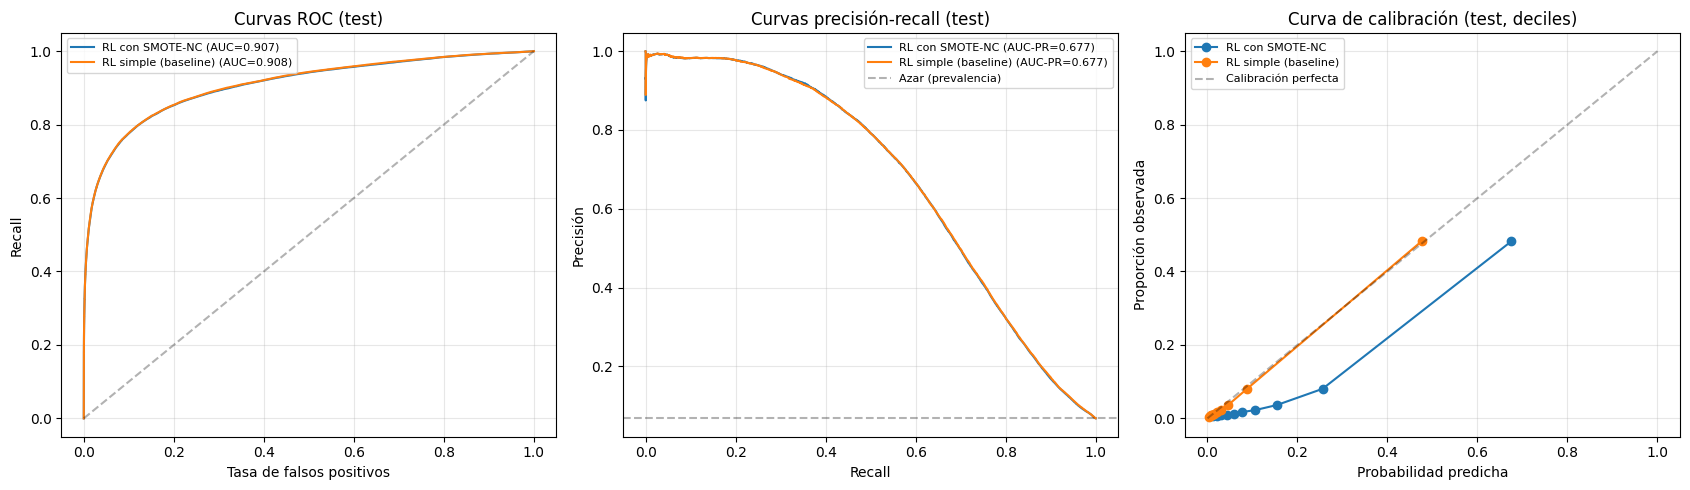

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for k, p in probas_te.items():
    fpr, tpr, _ = roc_curve(y_te, p)
    axes[0].plot(fpr, tpr, label=f"{k} (AUC={roc_auc_score(y_te, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_te, p)
    axes[1].plot(rc, pr, label=f"{k} (AUC-PR={average_precision_score(y_te, p):.3f})")
    frac, media = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    axes[2].plot(media, frac, "o-", label=k)
axes[0].plot([0, 1], [0, 1], "k--", alpha=.3)
axes[0].set(title="Curvas ROC (test)", xlabel="Tasa de falsos positivos", ylabel="Recall")
axes[1].axhline(y_te.mean(), color="k", ls="--", alpha=.3, label="Azar (prevalencia)")
axes[1].set(title="Curvas precisión-recall (test)", xlabel="Recall", ylabel="Precisión")
axes[2].plot([0, 1], [0, 1], "k--", alpha=.3, label="Calibración perfecta")
axes[2].set(title="Curva de calibración (test, deciles)", xlabel="Probabilidad predicha", ylabel="Proporción observada")
for a in axes:
    a.legend(fontsize=8); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 5. Interpretación

Las cifras corresponden a la ejecución en Colab (scikit-learn 1.6.1); los valores exactos están en las tablas de arriba.

**1. El ajuste casi no cambia la discriminación.** Seis de las ocho combinaciones quedan empatadas en validación (AUC-PR entre 0.6655 y 0.6662, dentro de la tolerancia de 0.001). Solo L1 con `C = 0.0001` queda por debajo (0.660 con proporción 0.25 y 0.662 con 0.5): con esa regularización tan fuerte deja en cero 46 y 42 de las 53 columnas y pierde información. Con `C = 0.001`, L1 elimina entre 12 y 18 columnas sin perder AUC-PR, lo que confirma que varias categorías aportan poco. El AUC-PR de train (sobre el train real) y de validación es casi igual en todas las combinaciones: no hay sobreajuste.

**2. La proporción de sobremuestreo mueve el punto de operación, no el ranking.** Con 0.25 (train con 20% de casos) el modelo queda con recall ≈ 0.62 y precisión ≈ 0.62 en validación; con 0.5 (33% de casos), recall ≈ 0.71 y precisión ≈ 0.46. El AUC-PR es prácticamente el mismo. Más casos sintéticos hacen que el modelo marque más casos, igual que un umbral más bajo.

**3. Modelo elegido:** proporción 0.25, L2, `C = 0.0001`, por la regla de desempate (menor proporción, luego L2, luego el C menor). Todos los ajustes convergieron con `saga`.

**4. En test, SMOTE-NC no mejora la discriminación.** La regresión con SMOTE-NC y el baseline tienen prácticamente el mismo AUC-ROC (0.907 frente a 0.908) y el mismo AUC-PR (0.677); sus curvas ROC y precisión-recall se superponen. Como en la regresión balanceada, el tratamiento del desbalance no agrega capacidad de separar casos y no casos.

**5. Punto de operación con el umbral 0.5: el mejor equilibrio de las tres regresiones.** Detecta 30 790 de 48 907 casos (recall 0.63) con 19 006 falsas alarmas, unas 0.6 por cada caso real (precisión 0.62). Su F1 (0.62) es el más alto de las tres regresiones logísticas: el baseline tiene 0.60 (recall 0.47, precisión 0.82) y la balanceada 0.45 (recall 0.81, precisión 0.31). La razón es la proporción elegida: con 20% de casos en el train, el modelo queda en un punto intermedio entre no balancear y balancear por completo.

**6. Las probabilidades quedan algo infladas, menos que con el balanceo completo.** En el decil de mayor riesgo el modelo predice en promedio cerca de 0.68, frente a una proporción observada cercana a 0.48 (la regresión balanceada predecía cerca de 0.86). Es consecuencia de entrenar con más casos de bajo peso de los que hay en la realidad.

**7. Comparación con Khan et al. (2022).** Khan obtuvo su mejor clasificación con regresión logística y SMOTE, sobre 821 registros (89 casos de bajo peso). Aquí, con más de 200 000 casos de bajo peso en train, SMOTE-NC no mejora la discriminación respecto del baseline; solo cambia el punto de operación. Una explicación plausible es que, con tantos casos reales de la clase minoritaria, el modelo ya tiene suficientes ejemplos y los sintéticos no aportan información nueva.

**8. Costo.** Generar los casos sintéticos tomó unos 39 minutos en Colab y la grilla otros 21, frente a segundos o pocos minutos de la regresión balanceada, para llegar a la misma capacidad de discriminación.

## 6. Limitaciones

- **`DUR_EMB_PARTO` se conoce al momento del parto, no antes.** El encuadre es "información registrada al momento del parto, antes del pesaje"; no es una predicción prenatal.
- **Umbral fijo en 0.5**, como en los papers. Precisión, recall y F1 dependen de esa elección; AUC-ROC y AUC-PR no.
- **La prevalencia del test (6.81%) es mayor que la de train (6.32%).** Precisión y F1 en test no son directamente comparables con validación.
- **El peso tiene redondeo en 2500 g** (16 353 registros exactos), lo que mete ruido en la etiqueta justo en el umbral.
- **El test no incluye diciembre de 2025.**
- **El CNV no registra variables clínicas** (controles prenatales, anemia, hipertensión, IMC), que podrían mejorar la predicción.
- Solo se probaron dos proporciones de sobremuestreo (0.25 y 0.5); el balance total no entra en memoria. `k_neighbors` no se ajustó, porque cada valor obliga a regenerar los casos sintéticos.
- No se exploró elastic-net intermedio (0 < `l1_ratio` < 1) ni valores de `C` fuera de la zona útil identificada en el notebook 03.
- No se verificó qué tan plausibles son los casos sintéticos (por ejemplo, la interpolación de `DUR_EMB_PARTO`, que da semanas no enteras).
- Una sola semilla de sobremuestreo y una sola partición de validación.